# Capítulos 4 e 5: Running inference e Exploring ONNX

Apresentação dos capítulos 4 e 5 de *Domain-Specific Small Language Models* (Guglielmo Iozzia, Manning, 2026), com os exemplos do livro prontos para rodar.

**A ideia central**
- **Capítulo 4:** rodar um LLM custa memória e tempo, e o gargalo quase sempre é a *memória*, não o cálculo. O capítulo ensina a medir isso.
- **Capítulo 5:** o ONNX é um formato padrão para otimizar e rodar o modelo em qualquer hardware. Ele prepara o terreno para a quantização (capítulo 6).

**Roteiro**

| Parte | Seções | Assunto |
|---|---|---|
| 1 · Capítulo 4 | 1–2 | Memória necessária e carregamento do modelo |
| | 3–5 | Gerar texto, few-shot e código |
| | Métricas | TTFT, TPOT, latência e throughput |
| | 6–9 | KV cache, memory-bound × compute-bound, batching, tempo de geração |
| 2 · Capítulo 5 | 10–13 | Formato ONNX, operadores, ONNX Runtime e providers |
| | 14–17 | BERT em CPU e GPU, GPT-2, otimização do grafo e IOBinding |
| Fechamento | | Conclusão e pontos de atenção |
| Apêndice | A–B | LM-Eval e DeepSpeed (opcionais) |

**Como usar no Google Colab**
1. *Arquivo › Fazer upload de notebook* e escolha este arquivo.
2. *Ambiente de execução › Alterar o tipo de ambiente de execução* e selecione **GPU T4**.
3. *Ambiente de execução › Executar tudo*. O primeiro download do modelo (~10 GB) leva alguns minutos.

**Dica para apresentar:** rode tudo antes da aula. O Colab guarda as saídas no notebook, então na aula você mostra os resultados prontos e roda ao vivo só as células rápidas (seções 1, 7, 8, 11 e 12).

## Configuração

In [ ]:
# Modelo do capítulo 4 (2,7 bilhões de parâmetros, ~10 GB de download).
MODEL_ID = "EleutherAI/gpt-neo-2.7B"
# Teste rápido: descomente a linha abaixo.
# MODEL_ID = "EleutherAI/gpt-neo-125M"

# O livro repete cada medição do capítulo 4 20 vezes. 3 já mostra a diferença
# e evita esperar ~17 minutos no teste sem KV cache.
N_RUNS = 3

# Capítulo 5: o livro usa 200 amostras do SQuAD nos benchmarks do BERT.
N_SAMPLES = 200

PROMPT = "The story so far: in the beginning, the universe was created."

In [ ]:
!pip install -q transformers accelerate onnx onnxruntime-gpu datasets

# Parte 1 · Capítulo 4: Running inference

Antes de otimizar um modelo, é preciso saber **quanta memória ele usa**, **quanto tempo leva para gerar texto** e **onde está o gargalo**. Esse capítulo dá as ferramentas para medir isso, que são a base das técnicas de otimização e quantização dos capítulos 5, 6 e 9.

**Modelo de referência:** GPT-Neo 2.7B, da EleutherAI. É uma réplica aberta da arquitetura do GPT-3, treinada no dataset *Pile*. Não é mais desenvolvido, mas é ótimo para estudar: tudo o que vale para ele vale para qualquer LLM da biblioteca Transformers.

**Hardware de referência:** GPU NVIDIA T4, a do Colab gratuito.

| Característica da T4 | Valor | Para que serve na conta |
|---|---|---|
| Memória | 16 GB | Limite para pesos + KV cache |
| Banda de memória | 300 GB/s (valor do livro) | Velocidade para *ler* dados da memória |
| Capacidade de cálculo | 65 TFLOPS (FP16 com tensor cores) | Velocidade para *calcular* |

## 1. Quanta memória o modelo precisa? (4.1.1 e 4.2)

O Accelerate tem um comando que estima o tamanho do modelo em cada precisão, sem baixar os pesos.

**Precisão** é quantos bits cada parâmetro (peso) ocupa:

| Formato | Bits | Bytes por parâmetro |
|---|---|---|
| float32 (FP32) | 32 | 4 |
| float16 (FP16) | 16 | 2 |
| int8 | 8 | 1 |
| int4 | 4 | 0,5 |

Cada vez que a precisão cai pela metade, a memória cai pela metade. Essa é a ideia da **quantização** (capítulo 6).

In [ ]:
!accelerate estimate-memory $MODEL_ID

Loading pretrained config for `EleutherAI/gpt-neo-2.7B` from `transformers`...
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
┌────────────────────────────────────────────────────────────┐
│     Memory Usage for loading `EleutherAI/gpt-neo-2.7B`     │
├───────┬─────────────┬──────────┬───────────────────────────┤
│ dtype │Largest Layer│Total Size│    Training using Adam    │
├───────┼─────────────┼──────────┼───────────────────────────┤
│float32│  490.79 MB  │ 9.89 GB  │          39.57 GB         │
│float16│   245.4 MB  │ 4.95 GB  │          19.79 GB         │
│  int8 │   122.7 MB  │ 2.47 GB  │            N/A            │
│  int4 │   61.35 MB  │ 1.24 GB  │            N/A            │
└───────┴─────────────┴──────────┴───────────────────────────┘


**Por que 9,89 GB e não 10,8 GB (2,7 bi × 4 bytes)?** O modelo tem cerca de 2,65 bilhões de parâmetros, não exatamente 2,7, e a ferramenta divide por 1024³ (gibibytes) em vez de 10⁹.

### A fórmula do livro para a memória de inferência

$$\text{memória (GB)} = \frac{4 \times P}{32 \div F} \times 1{,}2$$

| Termo | Significado |
|---|---|
| $4$ | bytes por parâmetro em FP32 |
| $P$ | número de parâmetros, em bilhões |
| $F$ | bits da precisão escolhida (32, 16, 8) |
| $32 \div F$ | quantas vezes a precisão é menor que FP32 |
| $1{,}2$ | 20% de folga para o KV cache e outros overheads da inferência |

**Exemplo (GPT-Neo 2.7B em FP32):** $\frac{4 \times 2{,}7}{32 \div 32} \times 1{,}2 = 10{,}8 \times 1{,}2 = 12{,}96$ GB.

A fórmula serve para escolher a GPU antes de fazer o deploy.

In [ ]:
def memoria_gb(params_bilhoes, bits):
    return (4 * params_bilhoes) / (32 / bits) * 1.2

for nome, p in [("GPT-Neo 2.7B", 2.7), ("Mistral 7B", 7.0)]:
    for bits in (32, 16, 8):
        print(f"{nome:13} {bits:2} bits: {memoria_gb(p, bits):6.2f} GB")

GPT-Neo 2.7B  32 bits:  12.96 GB
GPT-Neo 2.7B  16 bits:   6.48 GB
GPT-Neo 2.7B   8 bits:   3.24 GB
Mistral 7B    32 bits:  33.60 GB
Mistral 7B    16 bits:  16.80 GB
Mistral 7B     8 bits:   8.40 GB


## 2. Carregar o modelo (4.1.1)

- **`GPT2Tokenizer`:** o GPT-Neo usa o mesmo vocabulário do GPT-2 (50.257 tokens). O tokenizer converte texto em números (*token ids*) e vice-versa.
- **`GPTNeoForCausalLM`:** a classe do GPT-Neo para *causal language modeling*, ou seja, prever o próximo token.
- **`device_map="auto"`:** o Accelerate coloca o máximo de camadas na GPU. O que não couber vai para a RAM e, em último caso, para o disco. O código de inferência continua o mesmo.
- O modelo é carregado em **float32** (o padrão), que cabe na T4.

A saída `{'': 0}` significa que o modelo inteiro coube na GPU 0.

In [ ]:
import torch
from transformers import GPTNeoForCausalLM, GPT2Tokenizer

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_ID)
model = GPTNeoForCausalLM.from_pretrained(MODEL_ID, device_map="auto")
# O livro ainda chama model.to(device). Com device_map="auto" o Accelerate
# já posicionou as camadas, então omitimos para evitar avisos.

# {'': 0} = tudo na GPU 0. Versões novas do transformers não criam o atributo
# quando o modelo inteiro cabe num só dispositivo; aí mostramos o dispositivo.
print(getattr(model, "hf_device_map", model.device))

Device: cuda


Loading weights:   0%|          | 0/420 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-2.7B
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...31}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...30}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cuda:0


## 3. Completar texto (4.1.1)

O fluxo é sempre o mesmo: **tokenizar → mover para o device do modelo → `generate` → decodificar**.

### Os parâmetros do `generate`

| Parâmetro | O que faz |
|---|---|
| `input_ids` | O prompt convertido em números. Este prompt vira 14 tokens. |
| `do_sample=True` | **Sorteia** o próximo token de acordo com as probabilidades. Com `False`, escolhe sempre o mais provável (*greedy*) e o texto sai igual em toda execução. |
| `temperature=0.9` | Ajusta as probabilidades antes do sorteio. Abaixo de 1, o favorito fica mais forte (texto mais previsível); acima de 1, as chances se equilibram (texto mais criativo e mais desconexo). |
| `max_length=200` | Tamanho máximo **contando o prompt**: com 14 tokens de prompt, gera até 186 novos. Para antes se o modelo gerar o token de fim de texto. |
| `pad_token_id=50256` | O token `<|endoftext|>`, usado como enchimento. O GPT-Neo não tem token de padding próprio. Com um prompt só, apenas evita um aviso. |

Valor padrão que também influencia: **`top_k=50`**, que restringe o sorteio aos 50 tokens mais prováveis.

**Efeito da temperatura** (exemplo com três tokens candidatos):

| Temperatura | Token A | Token B | Token C |
|---|---|---|---|
| 0.5 | 84% | 11% | 4% |
| **0.9** (livro) | **66%** | **22%** | **12%** |
| 1.0 | 63% | 23% | 14% |
| 2.0 | 48% | 29% | 23% |

**Para experimentar ao vivo:** rode de novo com `temperature=0.3`, depois com `1.5`, depois com `do_sample=False`.

A saída começa repetindo o prompt, porque ele faz parte da sequência gerada.

In [ ]:
input_ids = tokenizer(PROMPT, return_tensors="pt").input_ids.to(model.device)

generated_ids = model.generate(input_ids,
                               do_sample=True,
                               temperature=0.9,
                               max_length=200,
                               pad_token_id=50256)
print(tokenizer.decode(generated_ids[0]))

The story so far: in the beginning, the universe was created. Then it expanded to form many other dimensions, but with a barrier between them. This barrier was the Dark Energy, an unspeakably dark and powerful form of energy.

One day as a young infant, a woman, named Mary, was placed on a spaceship travelling from Earth into interdimensional space when her mother died. Mary watched the blackness of space grow and expand until it engulfed her small body. As she floated through this darkness her father appeared, and he spoke to her.

“I love you.”

And he held her for a moment before she passed into the darkness. Her father then flew to the next dimension, and his small child flew with him.

The blackness of the void.

The ship’s engines ignited and they sped towards the other end of the universe. They sped and sped, and as they sped they began to tear apart and


### Vários prompts de uma vez

Para processar prompts de tamanhos diferentes juntos, eles precisam virar um tensor retangular. Os mais curtos são completados com o token de padding.

- **`padding_side = "left"`:** modelos *decoder* (GPT) continuam o texto a partir do **último** token. Se o padding ficasse à direita, os tokens vazios ficariam entre o prompt e a resposta.
- **`pad_token = eos_token`:** reaproveita o token de fim de texto como padding.
- **`torch.no_grad()`:** desliga o cálculo de gradientes, que só serve para treino. Economiza memória e tempo.
- **`batch_decode(..., skip_special_tokens=True)`:** decodifica todas as sequências e remove o padding.

In [ ]:
prompts = ["Once there was a man ",
           "The weather today will be ",
           "A great soccer player must "]

tokenizer.padding_side = "left"          # decoder: a geração continua do último token
tokenizer.pad_token = tokenizer.eos_token
encoding = tokenizer(prompts, padding=True, return_tensors="pt").to(model.device)

with torch.no_grad():
    generated_ids = model.generate(**encoding,
                                   do_sample=True,
                                   temperature=0.9,
                                   max_length=50,
                                   pad_token_id=50256)

for texto in tokenizer.batch_decode(generated_ids, skip_special_tokens=True):
    print("---------")
    print(texto)

---------
Once there was a man   
Who was a scholar, who was a poet;   
Who was a great thinker,   
And who was a great artist,   
And who did a lot of
---------
The weather today will be ___________/very cold ___________/cold ___________." The weather now is ___________/very sunny ___________."

2. The weather now is ___________/very sunny ________
---------
A great soccer player must  
have a great head.

**A DIFFERENT PLAYER, A DIFFERENT WAR?**

_To what extent do you think the United States soccer team would benefit from the


## 4. Few-shot learning (4.1.2)

**Few-shot** é colocar alguns exemplos resolvidos no prompt. O modelo reconhece o padrão e o aplica a casos novos, **sem nenhum treino**. Aqui, os exemplos ensinam a classificar o sentimento de frases sobre filmes.

O modelo não só responde: ele continua gerando novos pares `Sentence` / `Sentiment` no mesmo formato, até atingir `max_length`.

A geração é aleatória (`do_sample=True`): modelos pré-treinados sem filtro às vezes geram conteúdo inadequado. Rode antes de apresentar.

In [ ]:
prompt = """
Sentence: This movie is very nice.
Sentiment: positive

#####

Sentence: I hated this movie, it sucks.
Sentiment: negative

#####

Sentence: This movie was actually pretty funny.
Sentiment: positive

#####

Sentence: This movie could have been better.
Sentiment: neutral
"""
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(model.device)

generated_ids = model.generate(input_ids,
                               do_sample=True,
                               temperature=0.9,
                               max_length=200,
                               pad_token_id=50256)
print(tokenizer.decode(generated_ids[0]))


Sentence: This movie is very nice.
Sentiment: positive

#####

Sentence: I hated this movie, it sucks.
Sentiment: negative

#####

Sentence: This movie was actually pretty funny.
Sentiment: positive

#####

Sentence: This movie could have been better.
Sentiment: neutral

#####

Sentence: This movie will probably be bad, but I'm gonna watch it anyway.
Sentiment: positive

#####

Sentence: This movie doesn't matter to me at all.
Sentiment: positive

#####

Sentence: This movie made me laugh.
Sentiment: positive

#####

Sentence: This movie was very funny.
Sentiment: positive

#####

Sentence: This movie made me laugh.
Sentiment: positive

#####

Sentence


## 5. Geração de código (4.1.3)

O GPT-Neo também gera código porque o *Pile* inclui muitos repositórios do GitHub. O formato `Instruction: … Answer:` indica o que se espera.

No livro, a primeira resposta está certa (`return x[::-1]`), mas o modelo continua escrevendo até o limite de tokens, inclusive código com erro. **Código gerado sempre precisa de revisão.**

O próprio autor avisa: modelos pré-treinados como o GPT-Neo não são feitos para uso direto. Precisam de fine-tuning, LoRA ou RAG para o domínio. Aqui o objetivo é entender o que acontece por trás da API de geração.

In [ ]:
prompt = """Instruction: Generate a Python function that lets you reverse a list of integers.

Answer: """
input_ids = tokenizer(prompt, return_tensors="pt").input_ids.to(model.device)

generated_ids = model.generate(input_ids,
                               do_sample=True,
                               temperature=0.9,
                               max_length=200,
                               pad_token_id=50256)
print(tokenizer.decode(generated_ids[0]))

Instruction: Generate a Python function that lets you reverse a list of integers.

Answer: 

Here it is:
''.join([listOfInvertedIntegers[::-1] for listOfInvertedIntegers in inverted_list])

A:

It is a good idea to make these questions a bit shorter, so that people know they are answered.
This answer shows all the steps you need to follow to construct an algorithm for your problem. It's a bit long, but I hope it helps you a little.

Find a function to "reverse" an object. (this is a really bad idea, as it leads to lots of "reverse" questions)
Write the Python code for the function.
Call that function to reverse your object.

(note: for Python, you want to use the function "map" instead of "filter" because it has more mathematical elegance).
Step 1:
"


## 6. KV cache (4.3.1)

### As duas fases da geração

1. **Prefill:** o modelo processa **todos os tokens do prompt de uma vez, em paralelo**, e preenche o KV cache. Nenhum token é gerado ainda. Determina o TTFT.
2. **Decodificação (autoregressiva):** o modelo gera **um token por vez**. Cada token novo entra na sequência e o processo se repete. Determina o TPOT.

### O que são Q, K e V

Na atenção, cada token gera três vetores:
- **Q** (*query*): o que esse token está procurando nos outros;
- **K** (*key*): a "etiqueta" de cada token, comparada com as queries;
- **V** (*value*): o conteúdo de cada token, que é combinado de acordo com essa comparação.

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

### Por que o cache acelera

Os vetores K e V dos tokens **antigos não mudam**. Sem cache, a cada token novo o modelo recalcula K e V de toda a sequência. Com cache, ele calcula só os do token novo e reaproveita o resto da memória.

**Custo:** um pouco mais de memória da GPU, que cresce com o número de tokens. É por isso que a fórmula de memória tem 20% de folga. No Transformers, `use_cache=True` já é o padrão, mas vale conferir em outros frameworks.

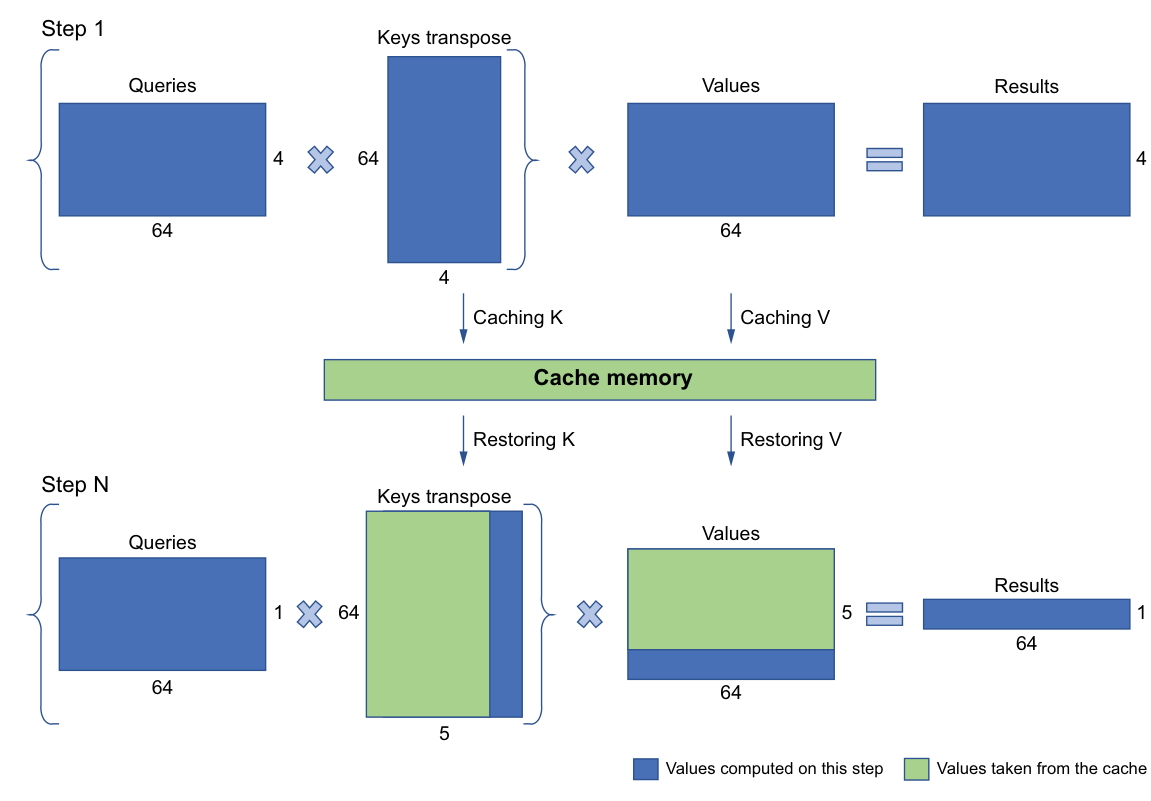

**Figura 4.1 · O cálculo (Q × Kᵀ) × V com KV cache**

**Passo 1 (prefill):** o prompt tem 4 tokens, cada um com 64 dimensões. O modelo calcula Q, K e V de todos eles e guarda K e V na memória de cache.

**Passo N (geração):** chega só 1 token novo. O modelo calcula apenas a linha desse token (em azul) e recupera do cache as linhas dos tokens anteriores (em verde). Sem o cache, teria que recalcular as matrizes inteiras a cada token.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

### Experimento: com e sem cache

O mesmo prompt é gerado `N_RUNS` vezes com o cache ligado e desligado. O único parâmetro que muda é `use_cache`.

**No livro (20 execuções na T4):** 10,28 s com cache e 51,98 s sem cache, cerca de **5× mais rápido**.

In [ ]:
import time
import numpy as np

input_ids = tokenizer(PROMPT, return_tensors="pt").input_ids.to(model.device)

for use_cache in (True, False):
    times = []
    for _ in range(N_RUNS):
        start = time.time()
        generated_ids = model.generate(input_ids,
                                       do_sample=True,
                                       temperature=0.9,
                                       max_length=200,
                                       pad_token_id=50256,
                                       use_cache=use_cache)
        times.append(time.time() - start)
    print(f"{'Using' if use_cache else 'No'} KV cache: "
          f"{round(np.mean(times), 3)} +- {round(np.std(times), 3)} seconds")

Using KV cache: 10.203 +- 0.011 seconds
No KV cache: 50.107 +- 1.812 seconds


## 7. Memory-bound ou compute-bound? (4.3.1)

Toda operação na GPU faz duas coisas: **ler dados da memória** e **calcular** com eles. O gargalo é a que demora mais.

### Passo 1: o ops/byte da GPU (característica do hardware)

Quantas operações a GPU consegue fazer para cada byte que lê da memória:

$$\text{ops/byte} = \frac{\text{capacidade de cálculo}}{\text{banda de memória}} = \frac{65 \times 10^{12}\ \text{FLOPS}}{300 \times 10^{9}\ \text{bytes/s}} \approx 216{,}7$$

Para a T4 trabalhar no limite, cada byte lido precisa ser usado em cerca de **217 operações**.

### Passo 2: a intensidade aritmética do modelo (característica do algoritmo)

Quantas operações o algoritmo faz para cada byte que lê ou escreve:

$$\text{intensidade aritmética} = \frac{\text{total de operações}}{\text{total de bytes movidos}}$$

### Passo 3: comparar

- **intensidade < ops/byte → memory-bound:** a GPU fica esperando dados. Acelerar a memória (ou mover menos bytes) ajuda; mais poder de cálculo não ajuda.
- **intensidade > ops/byte → compute-bound:** a GPU está no limite de cálculo.

### A conta para a atenção do GPT-Neo

O livro usa **N = 2048** (janela de contexto) e **d = 128** (dimensão de cada cabeça de atenção). Q, K, V e a saída O são matrizes N × d; S e P são N × N. Cada número em FP32 ocupa 4 bytes. A atenção é feita em três passos, e cada um lê da memória, calcula e grava o resultado:

| Passo | Operação | Bytes movidos | Operações (FLOPs) |
|---|---|---|---|
| 1 | Ler Q e K, calcular $S = QK^T$, gravar S | $2 \cdot 4Nd + 4N^2$ | $2d \cdot N^2$ (cada um dos $N^2$ elementos soma $d$ produtos) |
| 2 | Ler S, calcular $P = \text{softmax}(S)$, gravar P | $4N^2 + 4N^2$ | $3N^2$ (exponencial, soma e divisão) |
| 3 | Ler P e V, calcular $O = PV$, gravar O | $4(N^2 + Nd) + 4Nd$ | $2N \cdot Nd$ |

O termo $\sqrt{d_k}$ da fórmula da atenção é ignorado, porque é pequeno perto do resto.

**Resultado:** cerca de 71 MB movidos e 2,16 bilhões de operações, ou seja, **30,29 operações por byte**. Como 30 < 217, a atenção é **memory-bound** na T4.

In [ ]:
# GPU T4: 65 TFLOPS e 300 GB/s de banda de memória
ops_to_byte = 65e12 / 300e9
print(f"ops/byte da T4: {ops_to_byte:.1f}")

N, d = 2048, 128
total_memory_movement = (2 * 4 * (N * d)) + (4 * (N * N)) + (4 * ((N * N) + (N * d))) \
                        + (4 * (N * N)) + (4 * (N * N)) + (4 * (N * d))
total_compute = ((2 * d) * (N * N)) + (3 * (N * N)) + ((2 * N) * (N * d))
arithmetic_intensity = total_compute / total_memory_movement

print(f"total_memory_movement = {total_memory_movement}")
print(f"total_compute = {total_compute}")
print(f"arithmetic_intensity = {arithmetic_intensity:.2f} ops/byte")
print("=> memory-bound" if arithmetic_intensity < ops_to_byte else "=> compute-bound")

ops/byte da T4: 216.7
total_memory_movement = 71303168
total_compute = 2160066560
arithmetic_intensity = 30.29 ops/byte
=> memory-bound


### Complemento: a geração de tokens é ainda mais memory-bound

A conta acima é para a atenção sobre o contexto inteiro (N = 2048), parecida com a fase de prefill. Na **decodificação**, cada passo processa só **1 token**: cada peso do modelo é lido da memória (4 bytes em FP32) e usado em apenas 2 operações (uma multiplicação e uma soma). Isso dá cerca de **0,5 operação por byte**, centenas de vezes abaixo dos 217 da T4.

É por isso que o tempo de cada token depende quase só da **banda de memória** (seção 9), e por isso reduzir os bytes do modelo com quantização acelera tanto a geração.

## 8. Batching: quantas sequências cabem num lote? (4.3.2)

**Batching** é processar várias requisições na mesma passada. Os pesos lidos da memória uma vez servem para várias sequências, então a **intensidade aritmética aumenta** e a GPU fica menos memory-bound.

- **Batching estático:** vários prompts da mesma requisição.
- **Batching dinâmico:** requisições diferentes são enfileiradas e processadas juntas.

### O limite: memória livre para o KV cache

Cada token do lote ocupa espaço no KV cache:

$$\text{KV cache por token} = 2 \times \text{bytes} \times n_{\text{camadas}} \times d_{\text{modelo}}$$

| Termo | Significado |
|---|---|
| $2$ | uma matriz K e uma V |
| bytes | 4 em FP32 |
| $n_{\text{camadas}}$ | camadas de atenção do modelo |
| $d_{\text{modelo}}$ | dimensão do modelo (*hidden size*) |

**Conta do livro:** a T4 tem 16 GB e o modelo ocupa 12,96 GB, então sobram **3,04 GB**. Com 24 camadas e dimensão 2048: $2 \times 4 \times 24 \times 2048 = 393.216$ bytes por token, e $3{,}04\ \text{GB} \div 0{,}00039\ \text{GB/token} \approx 7.795$ tokens, ou seja, **3 sequências de 2048 tokens**.

### Quando usar

| Bom para | Ruim para |
|---|---|
| Processamento assíncrono (filas de documentos), em que o total importa mais que a espera | Chatbots: esperar a fila encher **aumenta a latência** que o usuário sente |

Para chatbots, as alternativas são uma GPU maior ou a **quantização**.

A célula abaixo compara os valores do livro com os lidos da configuração do modelo carregado.

In [ ]:
def batch_capacity(n_layers, model_dim, free_gb, num_bytes=4, seq_len=2048):
    kv_bytes_per_token = 2 * num_bytes * n_layers * model_dim
    tokens = free_gb * 1e9 / kv_bytes_per_token
    return kv_bytes_per_token, int(tokens), int(tokens // seq_len)

free_gb = 16 - 12.96  # T4 menos o GPT-Neo 2.7B em FP32 (fórmula do livro)

for origem, layers, dim in [("livro", 24, 2048),
                            ("config do modelo", model.config.num_layers, model.config.hidden_size)]:
    kv, tokens, seqs = batch_capacity(layers, dim, free_gb)
    print(f"{origem:17}: {layers} camadas, dim {dim} -> {kv:,} B/token, "
          f"{tokens:,} tokens, {seqs} sequências de 2048")

livro            : 24 camadas, dim 2048 -> 393,216 B/token, 7,731 tokens, 3 sequências de 2048
config do modelo : 32 camadas, dim 2560 -> 655,360 B/token, 4,638 tokens, 2 sequências de 2048


## 9. Estimar e medir o tempo de geração (4.3.3)

Como a decodificação é memory-bound, o tempo de cada token é basicamente o tempo de **ler todos os pesos da memória**:

$$\text{tempo/token} = \frac{\text{bytes do modelo}}{\text{banda de memória}} = \frac{2{,}7 \times 10^9 \times 4\ \text{bytes}}{300 \times 10^9\ \text{bytes/s}} \approx 36\ \text{ms}$$

O prefill processa todos os tokens do prompt numa única passada e é limitado pelo **cálculo**:

$$\text{prefill} = n_{\text{tokens}} \times \frac{\text{bytes do modelo}}{\text{capacidade de cálculo}} = 300 \times \frac{10{,}8 \times 10^9}{65 \times 10^{12}} \approx 50\ \text{ms}$$

$$\text{tempo total} = \text{prefill} + n_{\text{tokens}} \times \text{tempo/token} = 50\ \text{ms} + 300 \times 36\ \text{ms} \approx 10{,}85\ \text{s}$$

A estimativa supõe paralelismo perfeito e nenhum overhead. **No livro, o tempo medido foi 15,56 s**: a diferença vem de operações além do cálculo na GPU.

**Outras formas de acelerar a inferência** citadas pelo livro:
- **Operator fusion:** junta operações vizinhas numa só, reduzindo leituras e escritas na memória.
- **Quantização:** menos bits por peso, menos bytes para ler (capítulos 6 e 9).
- **Sparsity e distillation:** zerar partes do modelo, ou treinar um modelo menor imitando um maior.
- **Paralelismo:** dividir o modelo entre GPUs (tensor ou pipeline parallelism).

A primeira célula faz a estimativa usando o número real de parâmetros do modelo carregado. A segunda mede o tempo: repete a geração `N_RUNS + 1` vezes e descarta a primeira execução (o livro usa 21 e descarta 1).

In [ ]:
n_params = sum(p.numel() for p in model.parameters())
bytes_moved = n_params * 4                      # FP32
gpu_mem_bandwidth = 300e9                       # T4: 300 GB/s
gpu_compute = 65e12                             # T4: 65 TFLOPS
n_tokens = 300

time_per_token = bytes_moved / gpu_mem_bandwidth
prefill_time = n_tokens * (bytes_moved / gpu_compute)
total = prefill_time + n_tokens * time_per_token

print(f"parâmetros: {n_params / 1e9:.2f} bilhões")
print(f"tempo/token estimado: {time_per_token * 1000:.1f} ms")
print(f"prefill estimado: {prefill_time * 1000:.1f} ms")
print(f"total estimado para {n_tokens} tokens: {total:.2f} s")

parâmetros: 2.65 bilhões
tempo/token estimado: 35.4 ms
prefill estimado: 48.9 ms
total estimado para 300 tokens: 10.65 s


In [ ]:
max_length = 300
times = []
inference_runs = N_RUNS + 1   # o livro usa 21 e descarta a primeira

for _ in range(inference_runs):
    start = time.time()
    generated_ids = model.generate(input_ids,
                                   do_sample=True,
                                   temperature=0.9,
                                   max_length=max_length,
                                   pad_token_id=50256)
    times.append(time.time() - start)

print(f"Average Total Generation time: {round(np.mean(times[1:]), 3)} "
      f"+- {round(np.std(times[1:]), 3)} seconds")

Average Total Generation time: 15.892 +- 0.055 seconds


### Liberar a GPU antes do capítulo 5

In [ ]:
import gc
for nome in ("model", "generated_ids", "encoding"):
    globals().pop(nome, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memória da GPU em uso: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Memória da GPU em uso: 0.01 GB


# Parte 2 · Capítulo 5: Exploring ONNX

**ONNX** (*Open Neural Network Exchange*) é um **formato padrão de modelos**. Funciona como um "PDF dos modelos": você cria o modelo em qualquer framework (PyTorch, TensorFlow…), salva em ONNX, e qualquer leitor compatível consegue abri-lo.

- **Por que usar:** evita ficar preso a um framework ou fabricante (*lock-in*). O framework de hoje pode não ser o de amanhã.
- **História:** criado pelo Facebook em 2017, hoje é um projeto da Linux Foundation AI.
- **Dois projetos:** o **formato ONNX** (seções 10–11) e o **ONNX Runtime**, que executa os modelos (seções 12–13).

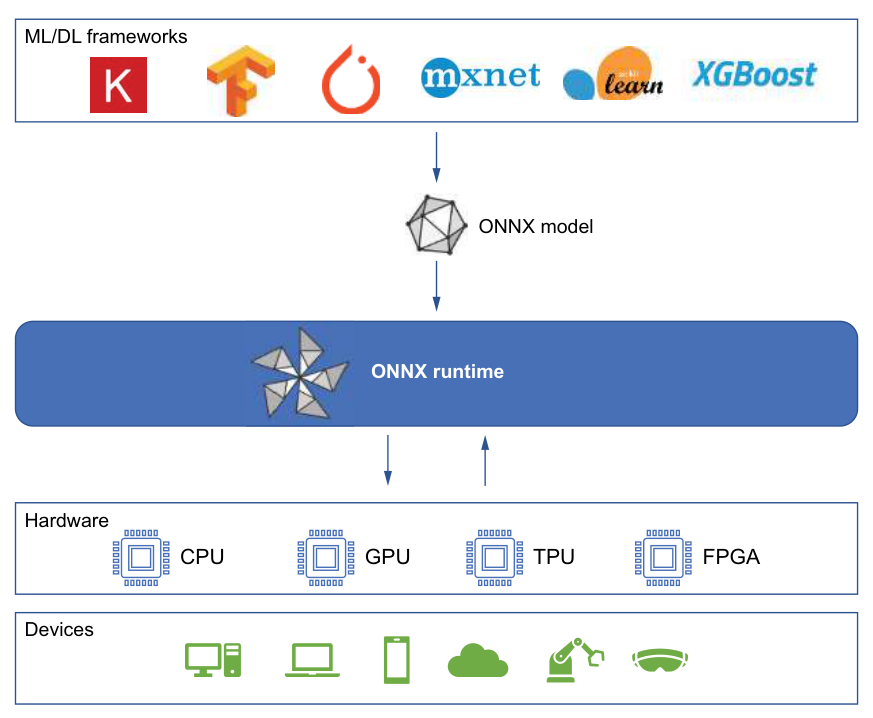

**Figura 5.1 · Visão geral do ONNX**

Modelos de vários frameworks (Keras, TensorFlow, PyTorch, MXNet, scikit-learn, XGBoost) são convertidos para o formato ONNX. O ONNX Runtime executa esse modelo em diferentes hardwares (CPU, GPU, TPU, FPGA) e dispositivos, do computador ao celular e à nuvem.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

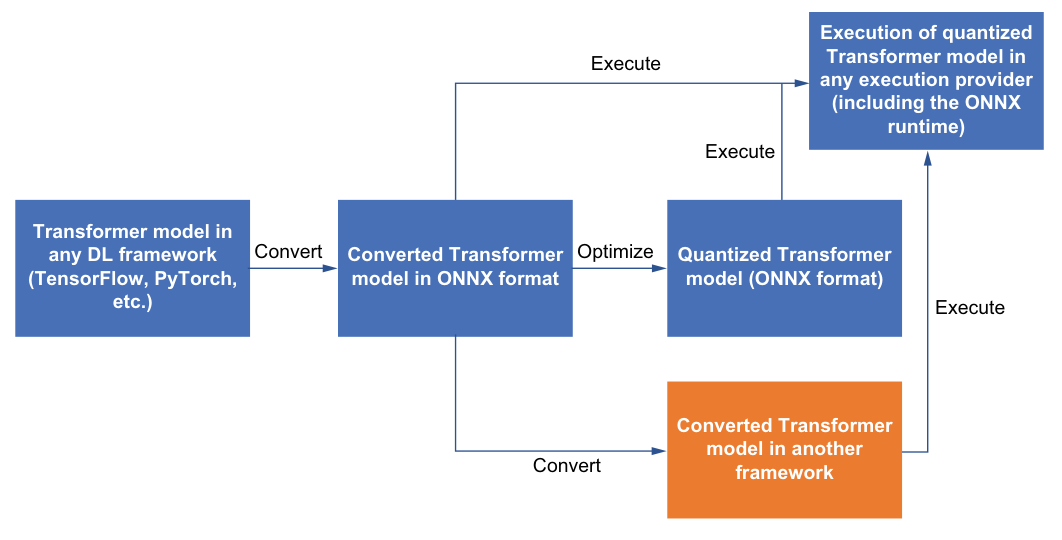

**Figura 5.3 · O que dá para fazer com um modelo em ONNX**

Depois de converter o modelo para ONNX, há três caminhos: executar direto, quantizar (capítulo 6) ou converter para outro framework. O caminho em laranja não é coberto pelo livro.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

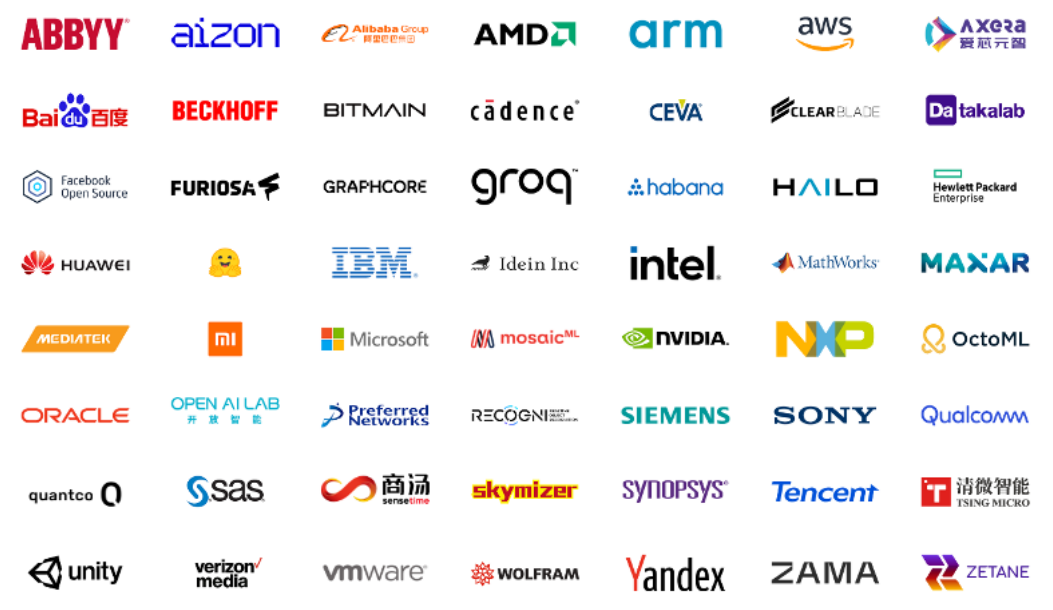

**Figura 5.2 · Organizações que apoiam o ONNX**

Criado pelo Facebook em 2017, hoje o ONNX é um projeto da Linux Foundation AI com apoio de empresas como Microsoft, Intel, NVIDIA, AMD, Qualcomm e IBM.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

## 10. Tipos ONNX (5.2)

O ONNX trabalha com **tensores** (arrays multidimensionais), cada um com um tipo de elemento, uma forma (*shape*) e os valores. No começo só existia float32; hoje há todos os tipos comuns, inclusive os de 8 bits usados na quantização (`INT8`, `FLOAT8…`).

A célula lista os tipos disponíveis.

In [ ]:
import re
from onnx import TensorProto

reg = re.compile('^[0-9A-Z_]+$')

values = {}
for att in sorted(dir(TensorProto)):
    if att in {'DESCRIPTOR'}:
        continue
    if reg.match(att):
        values[getattr(TensorProto, att)] = att
for i, att in sorted(values.items()):
    si = str(i)
    if len(si) == 1:
        si = " " + si
    print("%s: onnx.TensorProto.%s" % (si, att))

 1: onnx.TensorProto.FLOAT
 2: onnx.TensorProto.UINT8
 3: onnx.TensorProto.INT8
 4: onnx.TensorProto.UINT16
 5: onnx.TensorProto.INT16
 6: onnx.TensorProto.INT32
 7: onnx.TensorProto.INT64
 8: onnx.TensorProto.STRING
 9: onnx.TensorProto.BOOL
10: onnx.TensorProto.FLOAT16
11: onnx.TensorProto.DOUBLE
12: onnx.TensorProto.UINT32
13: onnx.TensorProto.UINT64
14: onnx.TensorProto.COMPLEX64
15: onnx.TensorProto.COMPLEX128
16: onnx.TensorProto.BFLOAT16
17: onnx.TensorProto.FLOAT8E4M3FN
18: onnx.TensorProto.FLOAT8E4M3FNUZ
19: onnx.TensorProto.FLOAT8E5M2
20: onnx.TensorProto.FLOAT8E5M2FNUZ
21: onnx.TensorProto.UINT4
22: onnx.TensorProto.INT4
23: onnx.TensorProto.FLOAT4E2M1
24: onnx.TensorProto.FLOAT8E8M0
25: onnx.TensorProto.UINT2
26: onnx.TensorProto.INT2
27: onnx.TensorProto.FLOAT6E2M3
28: onnx.TensorProto.FLOAT6E3M2


Um modelo ONNX é salvo com **protobuf**, um formato do Google para serializar dados estruturados de forma compacta e independente de linguagem. Cada parte do modelo é uma classe `*Proto`: `ModelProto` (o modelo), `GraphProto` (o grafo), `NodeProto` (um operador), `TensorProto` (um tensor) e assim por diante.

In [ ]:
import onnx
import pprint

pprint.pprint([p for p in dir(onnx)
               if p.endswith('Proto') and p[0] != '_'])

['AttributeProto',
 'DeviceConfigurationProto',
 'FunctionProto',
 'GraphProto',
 'IntIntListEntryProto',
 'MapProto',
 'ModelProto',
 'NodeDeviceConfigurationProto',
 'NodeProto',
 'OperatorProto',
 'OperatorSetIdProto',
 'OperatorSetProto',
 'OptionalProto',
 'SequenceProto',
 'ShardedDimProto',
 'ShardingSpecProto',
 'SimpleShardedDimProto',
 'SparseTensorProto',
 'StringStringEntryProto',
 'TensorProto',
 'TensorShapeProto',
 'TrainingInfoProto',
 'TypeProto',
 'ValueInfoProto']


## 11. Construir um modelo com a API ONNX: regressão linear (5.2)

Um modelo ONNX é um **grafo direcionado**:
- os **nós** são **operadores** (`MatMul`, `Add`, `Softmax`, `LayerNormalization`, `QuantizeLinear`…), que consomem entradas e passam resultados adiante;
- as **arestas** são **tensores tipados**.

A regressão linear $Y = XA + B$ vira dois operadores: `y = Add(MatMul(X, A), B)`.

Funções usadas:

| Função | O que faz |
|---|---|
| `make_tensor_value_info` | Declara uma entrada ou saída, com nome, tipo e forma (`None` = tamanho livre) |
| `make_node` | Cria um nó: operador, entradas e saídas |
| `make_graph` | Junta os nós num grafo, com as entradas e saídas |
| `make_model` | Embrulha o grafo num modelo, com metadados |
| `check_model` | Verifica se o modelo é consistente |

O ONNX é **fortemente tipado**: o tipo e a forma de cada entrada e saída precisam ser declarados.

**`ir_version` e `opset`:** a versão do formato do arquivo e a versão do conjunto de operadores. Fixamos os mesmos do livro (IR 9, opset 21) para garantir que o ONNX Runtime consiga ler o arquivo.

In [ ]:
from onnx import TensorProto
from onnx.helper import (
    make_model, make_node, make_graph,
    make_tensor_value_info, make_opsetid)
from onnx.checker import check_model

X = make_tensor_value_info('X', TensorProto.FLOAT, [None, None])
A = make_tensor_value_info('A', TensorProto.FLOAT, [None, None])
B = make_tensor_value_info('B', TensorProto.FLOAT, [None, None])
Y = make_tensor_value_info('Y', TensorProto.FLOAT, [None])

node1 = make_node('MatMul', ['X', 'A'], ['XA'])
node2 = make_node('Add', ['XA', 'B'], ['Y'])

graph = make_graph([node1, node2], 'lr', [X, A, B], [Y])
# O livro usa make_model(graph). Fixamos IR 9 e opset 21 (os do livro) porque
# versões novas do pacote onnx podem gerar um IR que o ONNX Runtime ainda não lê.
onnx_model = make_model(graph, ir_version=9, opset_imports=[make_opsetid("", 21)])

check_model(onnx_model)

with open("linear_regression.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

print(onnx_model)

ir_version: 9
graph {
  node {
    input: "X"
    input: "A"
    output: "XA"
    op_type: "MatMul"
  }
  node {
    input: "XA"
    input: "B"
    output: "Y"
    op_type: "Add"
  }
  name: "lr"
  input {
    name: "X"
    type {
      tensor_type {
        elem_type: 1
        shape {
          dim {
          }
          dim {
          }
        }
      }
    }
  }
  input {
    name: "A"
    type {
      tensor_type {
        elem_type: 1
        shape {
          dim {
          }
          dim {
          }
        }
      }
    }
  }
  input {
    name: "B"
    type {
      tensor_type {
        elem_type: 1
        shape {
          dim {
          }
          dim {
          }
        }
      }
    }
  }
  output {
    name: "Y"
    type {
      tensor_type {
        elem_type: 1
        shape {
          dim {
          }
        }
      }
    }
  }
}
opset_import {
  domain: ""
  version: 21
}



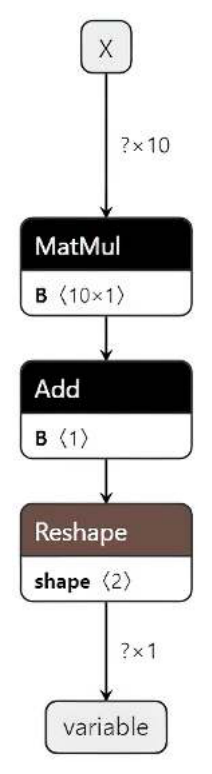

**Figura 5.4 · Uma regressão linear vista no Netron**

Cada caixa é um operador (nó do grafo) e cada seta é um tensor. A figura do livro mostra uma variação do exemplo, com os pesos fixos dentro do grafo (B ⟨10×1⟩) e um `Reshape` no fim. No nosso modelo, `A` e `B` são entradas. Para ver o grafo do arquivo que acabamos de criar, abra `linear_regression.onnx` em https://netron.app

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

## 12. Rodar com o ONNX Runtime (5.3)

O **ONNX Runtime (ORT)** executa modelos ONNX em servidores, celulares e dispositivos de borda. Ele aplica otimizações como fusão de kernels e quantização, e usa aceleração de hardware quando disponível. É usado principalmente para inferência; o treino fica com o framework original.

O fluxo é sempre o mesmo:
1. criar a sessão: `InferenceSession(caminho_do_modelo)`;
2. preparar as entradas como arrays NumPy, com os **nomes** certos (`session.get_inputs()` lista os nomes);
3. chamar `session.run(saídas, {nome: valor})`.

O que muda de modelo para modelo é o pré-processamento das entradas e o pós-processamento das saídas.

O livro mostra o padrão com uma entrada só; este modelo tem três (`X`, `A` e `B`), então passamos as três. Existe também o **ONNX Runtime Web** (WebAssembly e WebGL), para rodar modelos direto no navegador.

In [ ]:
from onnx import load

with open("linear_regression.onnx", "rb") as f:
    onnx_model = load(f)

import onnxruntime as rt
import numpy as np

session = rt.InferenceSession("linear_regression.onnx", providers=["CPUExecutionProvider"])
print("Entradas:", [i.name for i in session.get_inputs()])
print("Saídas:", [o.name for o in session.get_outputs()])

input_data = np.array([[2.0, 4.0, 6.0, 8.0]], dtype=np.float32)   # X do livro
A_data = np.array([[0.5], [1.0], [1.5], [2.0]], dtype=np.float32)
B_data = np.array([[1.0]], dtype=np.float32)

output_name = session.get_outputs()[0].name
result = session.run([output_name], {"X": input_data, "A": A_data, "B": B_data})

print(f"Output: {result[0]}")   # 2*0.5 + 4*1 + 6*1.5 + 8*2 + 1 = 31

Entradas: ['X', 'A', 'B']
Saídas: ['Y']
Output: [[31.]]


## 13. Execution providers (5.4)

**Execution providers** são os "drivers" do ONNX Runtime para cada hardware. O ORT divide o grafo e manda cada parte para o provider mais adequado disponível.

| Estáveis | Em preview |
|---|---|
| CPU, NVIDIA CUDA, NVIDIA TensorRT, Intel OpenVINO, Intel oneDNN, XNNPACK (ARM, WebAssembly), DirectML (Windows), AMD MIGraphX, AMD ROCm, Android NNAPI, Qualcomm QNN | TVM, Arm Compute Library, ARM-NN, CoreML (Apple), Rockchip NPU, Xilinx Vitis AI, Huawei CANN, Azure |

- `rt.get_available_providers()` mostra os que existem no ambiente.
- Ao criar a sessão, a lista `providers` define a **ordem de preferência**: aqui, CUDA se houver GPU, senão CPU.
- `session.get_providers()` mostra os que estão **de fato** em uso. Se só aparecer `CPUExecutionProvider` numa máquina com GPU, o ORT não encontrou a CUDA.

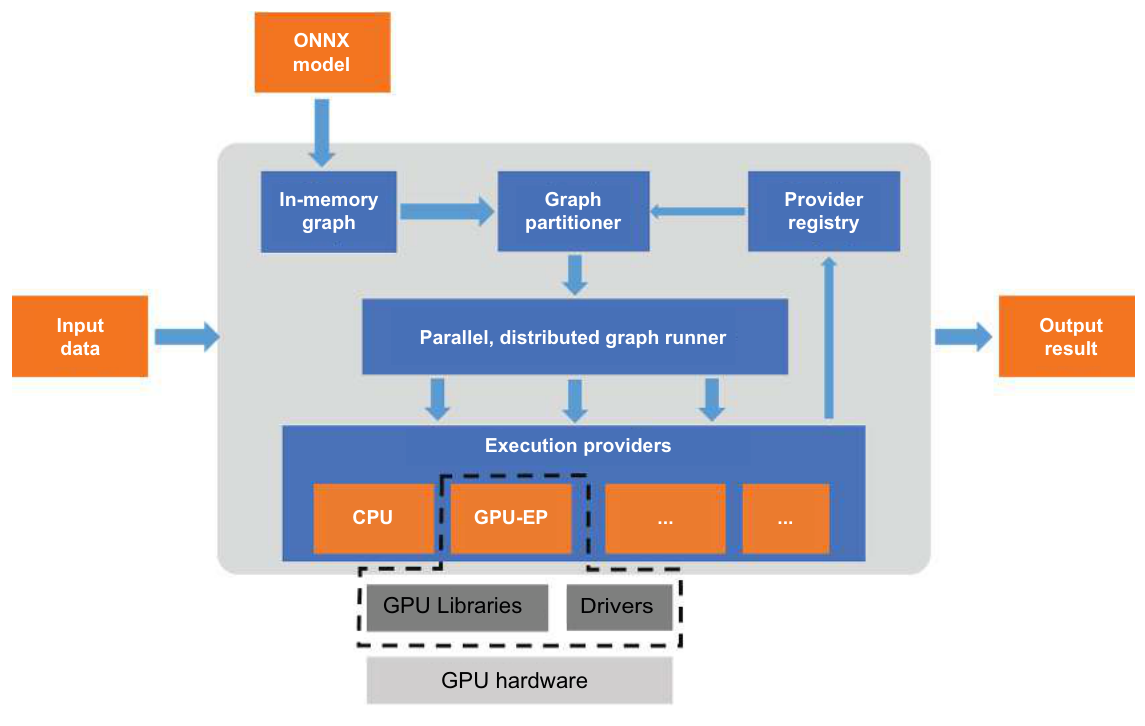

**Figura 5.5 · Como o ONNX Runtime executa um modelo**

O modelo é carregado como um grafo em memória. O particionador consulta o registro de providers e divide o grafo entre eles: cada parte roda no provider mais adequado (CPU, GPU…), que usa as bibliotecas e drivers do hardware.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

In [ ]:
import onnxruntime as rt

print(rt.get_available_providers())
# Com GPU e CUDA: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']

providers_list = ['CUDAExecutionProvider', 'CPUExecutionProvider']
sess = rt.InferenceSession("linear_regression.onnx", providers=providers_list)
print("Providers em uso:", sess.get_providers())

['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Providers em uso: ['CUDAExecutionProvider', 'CPUExecutionProvider']


## 14. BERT em CPU (5.5)

Agora um modelo de linguagem: o **`bert-base-uncased`**, para *question answering*, com 200 perguntas do dataset **SQuAD** (Stanford Question Answering Dataset). Cada amostra tem um `context` (um parágrafo da Wikipédia), uma `question` e a resposta.

Para *question answering*, o modelo devolve duas listas de pontuações (*logits*): **`start`**, a chance de cada token ser o início da resposta, e **`end`**, a chance de ser o fim. A resposta é o trecho do contexto entre o melhor início e o melhor fim.

**Atenção:** o `bert-base-uncased` não foi treinado para question answering. A "cabeça" de QA começa com pesos aleatórios (o aviso "newly initialized" é esperado), então as respostas não fazem sentido. O livro usa o modelo **só para comparar tempos** entre PyTorch e ONNX.

In [ ]:
import torch
from transformers import AutoModelForQuestionAnswering, BertTokenizer
from datasets import load_dataset

model_id = 'google-bert/bert-base-uncased'
tokenizer = BertTokenizer.from_pretrained(model_id)
model = AutoModelForQuestionAnswering.from_pretrained(model_id)
model.eval()

samples_count = N_SAMPLES
# O livro usa o nome curto "squad"; o Hugging Face hoje exige "dono/nome".
squad = load_dataset("rajpurkar/squad", split="validation[:" + str(samples_count) + "]")
squad[0]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForQuestionAnswering LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
qa_outputs.bias                            | MISSING    | 
qa_outputs.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

{'id': '56be4db0acb8001400a502ec',
 'title': 'Super_Bowl_50',
 'context': 'Super Bowl 50 was an American football game to determine the champion of the National Football League (NFL) for the 2015 season. The American Football Conference (AFC) champion Denver Broncos defeated the National Football Conference (NFC) champion Carolina Panthers 24–10 to earn their third Super Bowl title. The game was played on February 7, 2016, at Levi\'s Stadium in the San Francisco Bay Area at Santa Clara, California. As this was the 50th Super Bowl, the league emphasized the "golden anniversary" with various gold-themed initiatives, as well as temporarily suspending the tradition of naming each Super Bowl game with Roman numerals (under which the game would have been known as "Super Bowl L"), so that the logo could prominently feature the Arabic numerals 50.',
 'question': 'Which NFL team represented the AFC at Super Bowl 50?',
 'answers': {'text': ['Denver Broncos', 'Denver Broncos', 'Denver Broncos'],


### Exportar para ONNX

O `torch.onnx.export` **roda o modelo uma vez** com uma entrada de exemplo e **grava as operações** que acontecem (*tracing*). Por isso precisa de uma amostra de entrada.

| Argumento | Para que serve |
|---|---|
| `args` | A entrada de exemplo (aqui, a primeira pergunta do SQuAD) |
| `opset_version=15` | A versão do conjunto de operadores ONNX |
| `do_constant_folding=True` | Pré-calcula as partes do grafo que só dependem de constantes |
| `input_names`, `output_names` | Os nomes das entradas e saídas, usados depois no `session.run` |
| `dynamic_axes` | Quais eixos têm tamanho variável. Sem isso, o modelo só aceitaria o tamanho exato do exemplo. Aqui, o lote (eixo 0) e o número de tokens (eixo 1) |
| `dynamo=False` | Usa o exportador clássico, o mesmo do livro |

As entradas do BERT: `input_ids` (os tokens), `input_mask` (1 para tokens reais, 0 para padding) e `segment_ids` (0 para a pergunta, 1 para o contexto).

In [ ]:
import os

output_dir = os.path.join(".", "onnx_models")
onnx_model_filename = 'bert-base-uncased.onnx'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)
export_model_path = os.path.join(output_dir, onnx_model_filename)

tokenized_inputs = tokenizer(squad["question"][0],
                             squad["context"][0], return_tensors="pt")
inputs = {
        'input_ids':  tokenized_inputs['input_ids'],
        'input_mask': tokenized_inputs['attention_mask'],
        'segment_ids': tokenized_inputs['token_type_ids']
    }

with torch.no_grad():
    symbolic_names = {0: 'batch_size', 1: 'max_seq_len'}
    torch.onnx.export(model,
                      args=tuple(inputs.values()),
                      f=export_model_path,
                      opset_version=15,
                      do_constant_folding=True,
                      input_names=['input_ids',
                                   'input_mask',
                                   'segment_ids'],
                      output_names=['start', 'end'],
                      dynamic_axes={'input_ids': symbolic_names,
                                    'input_mask' : symbolic_names,
                                    'segment_ids' : symbolic_names,
                                    'start' : symbolic_names,
                                    'end' : symbolic_names},
                      dynamo=False)  # exportador clássico, o usado no livro

print("Exportado:", export_model_path)

/tmp/ipykernel_23278/3577746803.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model,
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:214: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/usr/local/lib/python3.13/dist-packages/transformers/integrations/sdpa_attention.py:124: TracerWarning: Converting a tensor to a Python

Exportado: ./onnx_models/bert-base-uncased.onnx


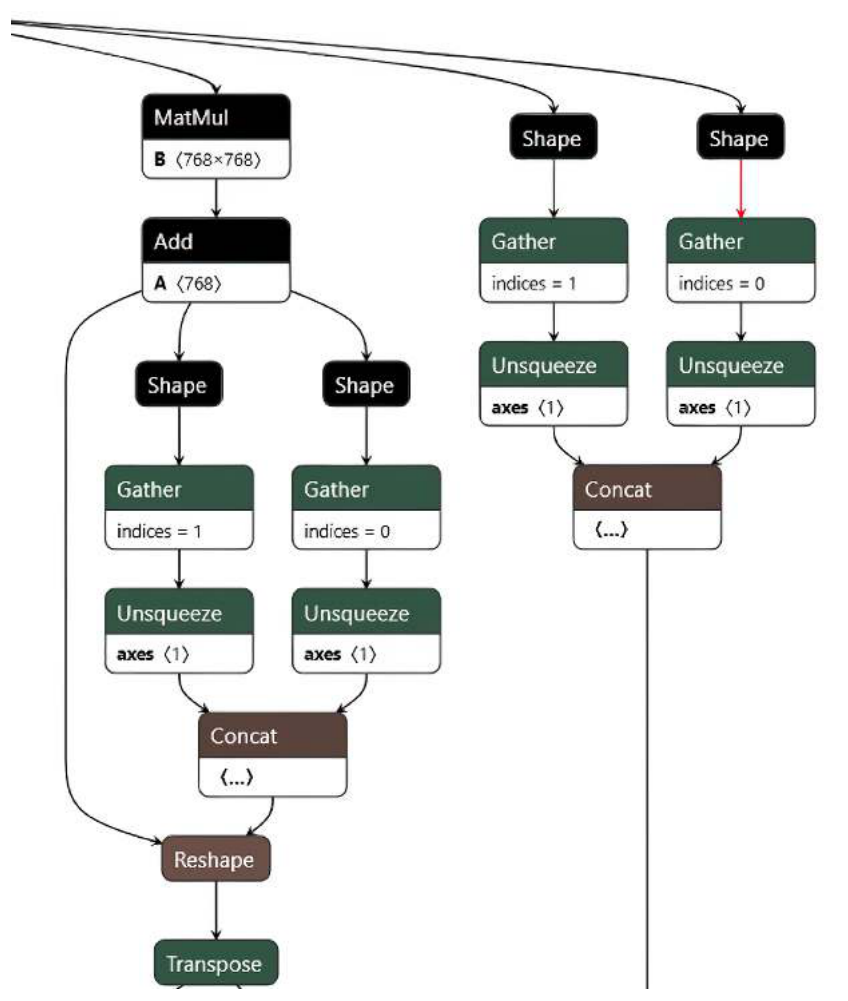

**Figura 5.6 · Parte do grafo ONNX do bert-base-uncased (um bloco de atenção)**

O mesmo tipo de grafo da regressão linear, só que muito maior: o arquivo que acabamos de exportar tem milhares de nós como estes. As caixas `MatMul` e `Add` com pesos 768×768 são a projeção da atenção.

*Fonte: G. Iozzia, Domain-Specific Small Language Models, Manning, 2026.*

### Validar: schema e saídas iguais às do PyTorch

A validação tem duas partes:
1. **`check_model(..., full_check=True)`:** confere se a estrutura do modelo é válida.
2. **`np.allclose`:** confere se os **números** batem com os do modelo original, dentro de uma tolerância:

$$|\text{saída}_{\text{ONNX}} - \text{saída}_{\text{PyTorch}}| \le \text{atol} + \text{rtol} \times |\text{saída}_{\text{PyTorch}}|$$

com `rtol = 1e-05` (tolerância relativa) e `atol = 1e-04` (tolerância absoluta). Pequenas diferenças são normais, porque a ordem das operações em ponto flutuante muda.

Na inferência com o ORT, as entradas são **arrays NumPy** (`return_tensors="np"`), não tensores PyTorch.

In [ ]:
from onnx.checker import check_model
import onnxruntime
import numpy as np

check_model(export_model_path, full_check=True)
print("Schema válido")

sess_options = onnxruntime.SessionOptions()
session = onnxruntime.InferenceSession(export_model_path,
    sess_options, providers=['CPUExecutionProvider'])

def tokenize(i, tensors):
    # truncation: alguns contextos do SQuAD passam do limite de 512 tokens do BERT
    return tokenizer(squad["question"][i], squad["context"][i],
                     return_tensors=tensors, truncation=True, max_length=512)

def to_ort_inputs(full_inputs):
    return {
        'input_ids':  full_inputs['input_ids'],
        'input_mask': full_inputs['attention_mask'],
        'segment_ids': full_inputs['token_type_ids']
    }

for i in range(10):
    with torch.no_grad():
        outputs = model(**tokenize(i, "pt"))
    ort_outputs = session.run(None, to_ort_inputs(tokenize(i, "np")))
    iguais = (np.allclose(ort_outputs[0], outputs.start_logits.cpu(), rtol=1e-05, atol=1e-04)
              and np.allclose(ort_outputs[1], outputs.end_logits.cpu(), rtol=1e-05, atol=1e-04))
    print(f"amostra {i}: {'saídas iguais' if iguais else 'DIFERENTES'}")

Schema válido
amostra 0: saídas iguais
amostra 1: saídas iguais
amostra 2: saídas iguais
amostra 3: saídas iguais
amostra 4: saídas iguais
amostra 5: saídas iguais
amostra 6: saídas iguais
amostra 7: saídas iguais
amostra 8: saídas iguais
amostra 9: saídas iguais


### Benchmark: PyTorch × ONNX Runtime na CPU

Tempo médio por inferência, com as entradas já tokenizadas.

**No livro:** PyTorch **455,49 ms**, ONNX Runtime **373,10 ms** (cerca de 18% mais rápido).

**Por que o ONNX é mais rápido:** o grafo é executado direto pelo runtime em C++, sem o overhead do Python, e já sai com algumas otimizações (como o constant folding).

A CPU do Colab é diferente da do livro: compare as **proporções**, não os valores absolutos.

In [ ]:
import time

pt_inputs = [tokenize(i, "pt") for i in range(samples_count)]
np_inputs = [to_ort_inputs(tokenize(i, "np")) for i in range(samples_count)]

def bench_pytorch(model, device):
    times = []
    with torch.no_grad():
        for inp in pt_inputs:
            inp = {k: v.to(device) for k, v in inp.items()}
            start = time.time()
            model(**inp)
            if device == "cuda":
                torch.cuda.synchronize()
            times.append((time.time() - start) * 1000)
    return np.mean(times)

def bench_ort(session):
    times = []
    for inp in np_inputs:
        start = time.time()
        session.run(None, inp)
        times.append((time.time() - start) * 1000)
    return np.mean(times)

print(f"PyTorch CPU Average inference time = {bench_pytorch(model, 'cpu'):.2f} ms")
print(f"OnnxRuntime cpu Average inference time = {bench_ort(session):.2f} ms")

PyTorch CPU Average inference time = 286.43 ms
OnnxRuntime cpu Average inference time = 234.97 ms


### Otimizar o grafo com o optimizer do ONNX Runtime

O `optimizer.optimize_model` do `onnxruntime.transformers` conhece a estrutura dos Transformers e **funde operações** típicas (por exemplo, todo o bloco de atenção num só operador). Por isso precisa saber o tipo do modelo e sua configuração:
- `model_type='bert'`;
- `num_heads=12`: cabeças de atenção do BERT base;
- `hidden_size=768`: dimensão do modelo.

**No livro:** 373,10 ms → **355,48 ms**. O ganho depende da CPU; em alguns processadores é pequeno.

In [ ]:
from onnxruntime.transformers import optimizer

optimized_model_path = os.path.join(output_dir, 'bert-base-uncased.onnx_opt_cpu.onnx')
optimized_model = optimizer.optimize_model(export_model_path,
    model_type='bert', num_heads=12, hidden_size=768)
optimized_model.save_model_to_file(optimized_model_path)

opt_session = onnxruntime.InferenceSession(optimized_model_path,
    sess_options, providers=['CPUExecutionProvider'])
print(f"OnnxRuntime cpu Average inference time = {bench_ort(opt_session):.2f} ms")

OnnxRuntime cpu Average inference time = 256.77 ms


## 15. BERT em GPU (5.6)

Para usar a GPU, basta trocar o provider para **`CUDAExecutionProvider`** (com o pacote `onnxruntime-gpu`). O modelo ONNX exportado é o mesmo.

O livro não mostra números para este caso. Repare em `Providers em uso`: precisa aparecer `CUDAExecutionProvider`.

Neste benchmark, as entradas ainda saem da CPU a cada chamada. A seção 17 (IOBinding) mostra como evitar essa cópia.

In [ ]:
if torch.cuda.is_available():
    model = model.to("cuda")

    session_gpu = onnxruntime.InferenceSession(export_model_path, sess_options,
        providers=['CUDAExecutionProvider'])
    print("Providers em uso:", session_gpu.get_providers())

    print(f"PyTorch GPU Average inference time = {bench_pytorch(model, 'cuda'):.2f} ms")
    print(f"OnnxRuntime gpu Average inference time = {bench_ort(session_gpu):.2f} ms")
else:
    print("Sem GPU: ative a GPU T4 em Ambiente de execução › Alterar o tipo.")

Providers em uso: ['CUDAExecutionProvider', 'CPUExecutionProvider']
PyTorch GPU Average inference time = 11.01 ms
OnnxRuntime gpu Average inference time = 9.48 ms


## 16. GPT-2 em GPU (5.6.1)

Os exemplos anteriores usam o BERT, um modelo **encoder-only**. Agora um **decoder-only**, o GPT-2 small:

| Tipo | Exemplo | Para que serve |
|---|---|---|
| Encoder-only | BERT | **Entender** texto: classificação, question answering |
| Decoder-only | GPT-2, GPT-Neo | **Gerar** texto, um token por vez |

A saída do modelo exportado são os **logits**: para cada posição, uma pontuação para cada um dos 50.257 tokens do vocabulário. O maior logit na última posição é o **próximo token previsto**.

**Adaptações em relação ao livro**, necessárias para exportar com o transformers atual:
- exportamos também a `attention_mask`, além de `input_ids`;
- desligamos o KV cache na exportação (`use_cache = False`);
- envolvemos o modelo numa classe pequena que devolve só os logits;
- usamos `gpt2.onnx` como nome do arquivo (o livro reaproveita `bert-base-uncased.onnx` por um erro de cópia).

Sem GPU, as células usam a CPU.

In [ ]:
import torch
from transformers import GPT2Tokenizer, AutoModelForCausalLM

model_id = 'openai-community/gpt2'
tokenizer = GPT2Tokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.eval().to(device)
# Versões novas do transformers devolvem o KV cache num objeto DynamicCache,
# que o exportador não aceita. Sem cache, a saída é só a dos logits.
model.config.use_cache = False

# O livro reaproveita o nome 'bert-base-uncased.onnx' aqui (erro de cópia); usamos gpt2.onnx.
export_model_path = os.path.join(output_dir, 'gpt2.onnx')

# O livro exporta só input_ids (return_attention_mask=False). Sem attention_mask,
# o transformers 5 usa a operação aten::diff, que o exportador não suporta.
# Por isso exportamos também a attention_mask.
tokenized_inputs = tokenizer(PROMPT,
                             return_tensors="pt")
tokenized_inputs.to(device)
inputs_sample = {
        'input_ids':  tokenized_inputs['input_ids'],
        'attention_mask': tokenized_inputs['attention_mask']
    }

# Envolvemos o modelo para que o grafo tenha só essas duas entradas e devolva os
# logits (versões novas do transformers têm parâmetros extras no forward).
class GPT2Logits(torch.nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, input_ids, attention_mask):
        return self.model(input_ids=input_ids, attention_mask=attention_mask).logits

seq_axes = {0: 'batch_size', 1: 'seq_len'}   # o livro não define; assim aceita prompts de qualquer tamanho
with torch.no_grad():
    torch.onnx.export(GPT2Logits(model),
                      (inputs_sample['input_ids'], inputs_sample['attention_mask']),
                      export_model_path,
                      export_params=True,
                      opset_version=15,
                      input_names=['input_ids', 'attention_mask'],
                      output_names=['logits'],
                      dynamic_axes={'input_ids': seq_axes,
                                    'attention_mask': seq_axes,
                                    'logits': seq_axes},
                      dynamo=False)
print("Exportado:", export_model_path)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

/tmp/ipykernel_23278/3810723154.py:39: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(GPT2Logits(model),
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:253: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if padding_mask is not None and padding_mask.shape[-1] > kv_length:


Exportado: ./onnx_models/gpt2.onnx


In [ ]:
import onnxruntime
import numpy

providers = (["CUDAExecutionProvider", "CPUExecutionProvider"]
             if torch.cuda.is_available() else ["CPUExecutionProvider"])

session = onnxruntime.InferenceSession(export_model_path, providers=providers)
onnx_input_ids = tokenizer(PROMPT,
                           return_tensors="np")
ort_inputs = {
    "input_ids": onnx_input_ids['input_ids'],
    "attention_mask": onnx_input_ids['attention_mask']
}

ort_outputs = session.run(None, ort_inputs)

# ort_outputs[0] são os logits: o maior na última posição é o próximo token previsto
next_token = int(ort_outputs[0][0, -1].argmax())
print("Providers em uso:", session.get_providers())
print("Próximo token previsto:", repr(tokenizer.decode(next_token)))

Providers em uso: ['CUDAExecutionProvider', 'CPUExecutionProvider']
Próximo token previsto: ' The'


### Otimização do grafo: níveis, offline e online

Converter para ONNX costuma aplicar boas otimizações, mas às vezes é preciso ir além. O ONNX Runtime tem **níveis de otimização do grafo**:

| Nível | O que faz |
|---|---|
| `ORT_DISABLE_ALL` | Nenhuma otimização |
| `ORT_ENABLE_BASIC` | **Constant folding** (pré-calcula partes que só dependem de constantes), remove nós redundantes (Identity, Dropout…) e faz fusões simples que não mudam o resultado |
| `ORT_ENABLE_EXTENDED` | Fusões mais complexas, aplicadas depois de dividir o grafo entre os providers, só em nós de CPU, CUDA ou ROCm |
| `ORT_ENABLE_ALL` | Tudo acima, mais mudanças no **layout** dos dados na memória (só para CPU) |

Duas formas de aplicar:
- **Offline:** otimiza uma vez e **salva o modelo otimizado no disco**. As próximas sessões já abrem otimizadas. É a melhor opção para produção.
- **Online:** otimiza **toda vez que a sessão é criada**. Simples, mas deixa a inicialização mais lenta, principalmente em modelos grandes.

In [ ]:
import time
import numpy as np
import onnxruntime as rt

# Os mesmos providers no passo 1 e no passo 2: o arquivo EXTENDED fica
# preso à configuração em que foi salvo.
providers = (["CUDAExecutionProvider", "CPUExecutionProvider"]
             if torch.cuda.is_available() else ["CPUExecutionProvider"])
offline_path = os.path.join(output_dir, "gpt2_extended_offline.onnx")

# PASSO 1 (uma vez só): otimizar com EXTENDED e salvar
so = rt.SessionOptions()
so.graph_optimization_level = rt.GraphOptimizationLevel.ORT_ENABLE_EXTENDED
so.optimized_model_filepath = offline_path
rt.InferenceSession(export_model_path, so, providers=providers)
print("Passo 1: modelo otimizado salvo em", offline_path)

# PASSO 2 (no uso real): abrir o arquivo salvo SEM otimizar de novo
so = rt.SessionOptions()
so.graph_optimization_level = rt.GraphOptimizationLevel.ORT_DISABLE_ALL
session_offline = rt.InferenceSession(offline_path, so, providers=providers)
print("Passo 2: sessão aberta com", session_offline.get_providers())

# Conferir: o modelo otimizado prevê o mesmo que o original
inp = tokenizer(PROMPT, return_tensors="np")
ort_inputs = {"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]}
original = rt.InferenceSession(export_model_path, providers=providers)
a = original.run(None, ort_inputs)[0]
b = session_offline.run(None, ort_inputs)[0]
print("Mesmos logits:", np.allclose(a, b, rtol=1e-03, atol=1e-03),
      "| próximo token:", repr(tokenizer.decode(int(b[0, -1].argmax()))))

# Comparar o tempo para ABRIR a sessão (a vantagem do offline)
def tempo_abertura(path, level, n=3):
    tempos = []
    for _ in range(n):
        so = rt.SessionOptions()
        so.graph_optimization_level = level
        inicio = time.time()
        rt.InferenceSession(path, so, providers=providers)
        tempos.append(time.time() - inicio)
    return min(tempos)

t_online = tempo_abertura(export_model_path, rt.GraphOptimizationLevel.ORT_ENABLE_EXTENDED)
t_offline = tempo_abertura(offline_path, rt.GraphOptimizationLevel.ORT_DISABLE_ALL)
print(f"Abrir online  (otimiza a cada vez): {t_online:.2f} s")
print(f"Abrir offline (já otimizado):       {t_offline:.2f} s")

Passo 1: modelo otimizado salvo em ./onnx_models/gpt2_extended_offline.onnx
Passo 2: sessão aberta com ['CUDAExecutionProvider', 'CPUExecutionProvider']
Mesmos logits: True | próximo token: ' The'
Abrir online  (otimiza a cada vez): 1.29 s
Abrir offline (já otimizado):       1.15 s


## 17. IOBinding (5.6.2)

**O problema:** por padrão, o ONNX Runtime coloca as entradas e saídas na **CPU**, seja qual for o formato (arrays NumPy, dicionários…). Quando o modelo roda na GPU, os dados são **copiados da CPU para a GPU** a cada chamada, e o resultado volta. Essas cópias são overhead puro.

**A solução:** o **IOBinding** diz ao ORT onde os dados já estão. Com ele, entradas e saídas ficam direto na GPU, no mesmo dispositivo em que o grafo roda.

| Função | O que faz |
|---|---|
| `session.io_binding()` | Cria o objeto de binding |
| `bind_input(...)` | Aponta uma entrada para um buffer que já está no device (`buffer_ptr` = endereço na memória) |
| `bind_output(...)` | Idem para a saída. Sem device, a saída fica na CPU |
| `run_with_iobinding(binding)` | Roda a inferência usando os bindings, no lugar de `run` |

O exemplo usa um modelo mínimo que soma dois tensores, mas a ideia é a mesma para LLMs:
1. **só as entradas** no device, com a saída voltando para a CPU;
2. **entradas e saída** no device, sem nenhuma cópia.

Sem GPU, as células usam a CPU só para mostrar a API.

In [ ]:
import torch

def model():
    class Model(torch.nn.Module):
        def __init__(self):
            super(Model, self).__init__()

        def forward(self, x, y):
            return x.add(y)

    return Model()

MODEL_FILE = 'add_model.onnx'   # o livro usa '.model.onnx'

type = torch.float32
sample_x = torch.ones(3, dtype=type)
sample_y = torch.zeros(3, dtype=type)

torch.onnx.export(model(), (sample_x, sample_y),
                  MODEL_FILE, input_names=["x", "y"], output_names=["z"],
                  dynamic_axes={"x": {0 : "array_length_x"}, "y":
                                {0: "array_length_y"}},
                  dynamo=False)

/tmp/ipykernel_23278/1656826897.py:19: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model(), (sample_x, sample_y),


In [ ]:
import onnxruntime as rt
import numpy as np

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
providers = ['CUDAExecutionProvider', 'CPUExecutionProvider']
session = rt.InferenceSession(MODEL_FILE, providers=providers)

x = torch.rand(5).to(DEVICE)
y = torch.rand(5).to(DEVICE)
x_tensor = x.contiguous()
y_tensor = y.contiguous()

DEVICE_INDEX = 0
np_type = np.float32
torch_type = torch.float32

def bind_inputs(binding):
    binding.bind_input(
        name='x',
        device_type=DEVICE,
        device_id=DEVICE_INDEX,
        element_type=np_type,
        shape=tuple(x_tensor.shape),
        buffer_ptr=x_tensor.data_ptr(),
        )
    binding.bind_input(
        name='y',
        device_type=DEVICE,
        device_id=DEVICE_INDEX,
        element_type=np_type,
        shape=tuple(y_tensor.shape),
        buffer_ptr=y_tensor.data_ptr(),
        )

# 1) Só as entradas no device; a saída volta para a CPU
binding = session.io_binding()
bind_inputs(binding)
binding.bind_output('z')
session.run_with_iobinding(binding)
print("Saída copiada para a CPU:", binding.copy_outputs_to_cpu()[0])

# 2) Entradas e saída no device
z_tensor = torch.empty(x_tensor.shape, dtype=torch_type,
    device=DEVICE).contiguous()

binding = session.io_binding()
bind_inputs(binding)
binding.bind_output(
    name='z',
    device_type=DEVICE,
    device_id=DEVICE_INDEX,
    element_type=np_type,
    shape=tuple(z_tensor.shape),
    buffer_ptr=z_tensor.data_ptr(),
)
session.run_with_iobinding(binding)
print("Saída direto no device:", z_tensor)
print("z == x + y:", torch.allclose(z_tensor, x + y))

Saída copiada para a CPU: [1.0234361 1.8548875 1.1186345 1.0776436 1.77108  ]
Saída direto no device: tensor([1.0234, 1.8549, 1.1186, 1.0776, 1.7711], device='cuda:0')
z == x + y: True


# Conclusão

**Capítulo 4: medir e diagnosticar**
- Memória de inferência ≈ $\frac{4P}{32 \div F} \times 1{,}2$. Treinar com Adam custa pelo menos 4× os pesos.
- LLMs em GPU costumam ser **memory-bound**: a GPU espera dados mais do que calcula (30 contra 217 ops/byte na atenção; ~0,5 na geração de cada token).
- **KV cache** (≈ 5× mais rápido) e **batching** (mais throughput, mais latência) são as primeiras alavancas.
- Dá para estimar o tempo de geração antes de rodar: tempo/token ≈ bytes do modelo ÷ banda de memória.
- **DeepSpeed** troca camadas por kernels otimizados: −18% de latência no livro.

**Capítulo 5: otimizar de forma portátil**
- **ONNX** separa o modelo do framework e do hardware: o modelo vira um grafo de operadores.
- O **ONNX Runtime** e seus **execution providers** escolhem o hardware.
- Exportar → validar (`check_model` + `allclose`) → otimizar: no livro, −18% na CPU só com a conversão e −22% com o optimizer.
- **IOBinding** evita cópias entre CPU e GPU.

**Próximo passo, capítulo 6:** quantização em 8 e 4 bits, inclusive com ONNX. Reduzir os bytes por peso ataca diretamente o gargalo de memória do capítulo 4.

## Pontos de atenção: números do livro que não fecham

O método do livro está certo. Só alguns números de exemplo precisam de ajuste:

| # | O livro diz | A conta mostra |
|---|---|---|
| 1 | GPT-Neo em FP16 precisa de 5,4 GB (e, na pág. 61, que em *half precision* são 12,96 GB) | Pela fórmula, FP16 dá **6,48 GB** (5,4 GB é sem o fator 1,2). 12,96 GB é o valor de **FP32** |
| 2 | KV cache com 24 camadas e dimensão 2048 → 3 sequências no lote | O modelo tem **32 camadas e dimensão 2560** (veja a seção 8): ~655 KB por token, ~2 sequências |
| 3 | T4 com 65 TFLOPS "em FP32 ou FP16" | 65 TFLOPS é o pico em **FP16** com tensor cores. Em FP32, a T4 faz cerca de **8,1 TFLOPS** |

**Consequência do item 3:** com FP32, o ops/byte da T4 seria $8{,}1 \times 10^{12} \div 300 \times 10^9 \approx 27$. A atenção sobre o contexto inteiro (30 ops/byte) ficaria no limite entre memory-bound e compute-bound. A geração de tokens (~0,5 op/byte) continua fortemente memory-bound, então a conclusão principal do livro se mantém.

# Apêndice · Exemplos opcionais do capítulo 4

Estes dois exemplos demoram para instalar e dependem das versões das bibliotecas. Por isso ficam no fim: se algum falhar, os exemplos anteriores já rodaram.

## A. Avaliação com LM-Eval (4.1.4)

Antes de colocar um LLM em produção, é preciso avaliar a qualidade das saídas. O **LM-Eval** (Evaluation Harness, da EleutherAI) é uma biblioteca open source (licença MIT) com **mais de 200 tarefas** de avaliação prontas. Também aceita tarefas próprias e modelos da OpenAI e modelos quantizados (GPTQ, GGUF, GGML).

O livro usa a tarefa **`wikitext`**: 62 artigos verificados da Wikipédia. Ela mede três métricas, todas **quanto menor, melhor**:

| Métrica | O que mede | No livro |
|---|---|---|
| `word_perplexity` | Poder de previsão, por palavra. Intuitivamente, entre quantas palavras o modelo fica em dúvida a cada passo | 13,94 |
| `byte_perplexity` | O mesmo, por byte de texto | 1,64 |
| `bits_per_byte` | Bits necessários, em média, para prever o próximo byte: $\log_2(\text{byte\_perplexity})$ | 0,71 |

Opções do comando: `--model` (o tipo de modelo), `--model_args` (qual modelo baixar do Hub e como carregar), `--tasks` (as tarefas) e `--device` (GPU ou CPU).

**Adaptação:** o livro instala pelo GitHub e usa `python main.py --model hf-causal`. Hoje o LM-Eval está no PyPI e o comando é `lm_eval --model hf`. `--limit 20` avalia só 20 documentos para ser rápido; tire para a avaliação completa.

In [ ]:
!pip install -q lm-eval
!lm_eval --model hf \
    --model_args pretrained=$MODEL_ID,dtype=float16 \
    --tasks wikitext \
    --device cuda:0 \
    --limit 20

2026-10-14:05:08:58 WARNING  [config.evaluate_config:337] --limit SHOULD ONLY BE USED FOR TESTING. REAL METRICS SHOULD NOT BE COMPUTED USING LIMIT.
2026-10-14:05:09:11 INFO     [_cli.run:392] Selected Tasks: ['wikitext']
2026-10-14:05:09:14 INFO     [evaluator:214] Setting random seed to 0 | Setting numpy seed to 1234 | Setting torch manual seed to 1234 | Setting fewshot manual seed to 1234
2026-10-14:05:09:14 INFO     [evaluator:239] Initializing hf model, with arguments: {'pretrained': 'EleutherAI/gpt-neo-2.7B', 'dtype': 'float16'}
2026-10-14:05:09:19 INFO     [models.huggingface:289] Using device 'cuda:0'
2026-10-14:05:09:21 INFO     [models.huggingface:582] Model parallel was set to False, max memory was not set, and device map was set to {'': 'cuda:0'}
Loading weights: 100% 420/420 [00:40<00:00, 10.45it/s]
[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-2.7B
Key                                               | Status     |  | 
---------------------------------

## B. DeepSpeed (4.3.4)

O **DeepSpeed** é uma biblioteca open source da Microsoft para treino e inferência eficientes. Destaques:
- **ZeRO** (*Zero Redundancy Optimizer*): divide os estados do otimizador, os gradientes e os pesos entre GPUs para treinar modelos maiores;
- **paralelismo de modelo** e treino em precisão mista;
- **kernels de inferência**: com `replace_with_kernel_inject=True`, troca as camadas do modelo por versões otimizadas e fundidas.

| Parâmetro do `init_inference` | Significado |
|---|---|
| `mp_size=1` | Quantas GPUs usar (paralelismo de modelo) |
| `dtype=torch.float16` | Precisão da inferência |
| `replace_method="auto"` | O DeepSpeed escolhe quais camadas substituir |
| `replace_with_kernel_inject=True` | Ativa a injeção de kernels otimizados |

No notebook, é preciso simular o launcher do DeepSpeed com variáveis de ambiente: `MASTER_ADDR` e `MASTER_PORT` (endereço para os processos se comunicarem), `RANK` (o número deste processo), `LOCAL_RANK` (qual GPU da máquina usar) e `WORLD_SIZE` (quantos processos/GPUs no total).

**No livro:** latência média de **10,5 s sem DeepSpeed e 8,6 s com DeepSpeed (−18%)**. Como toda otimização, pode alterar levemente a saída: é preciso validar a qualidade.

> ⚠️ **Não funciona com as versões atuais do Colab.** A injeção de kernels foi escrita para o transformers da época do livro. Com o transformers 5, a execução termina com `CUDA error: device-side assert triggered`. Depois desse erro, a GPU fica travada: é preciso reiniciar a sessão (*Ambiente de execução › Reiniciar sessão*). Na apresentação, use os números do livro.

In [ ]:
!pip install -q deepspeed

In [ ]:
import gc, os, time
import numpy as np
import torch
from transformers import GPTNeoForCausalLM, GPT2Tokenizer

for nome in ("model", "session", "session_gpu", "opt_session"):
    globals().pop(nome, None)
gc.collect()
torch.cuda.empty_cache()

# Simula o launcher do DeepSpeed dentro do notebook
os.environ['MASTER_ADDR'] = 'localhost'
os.environ['MASTER_PORT'] = '9999'
os.environ['RANK'] = "0"
os.environ['LOCAL_RANK'] = "0"
os.environ['WORLD_SIZE'] = "1"

import deepspeed
deepspeed.init_distributed()

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_ID)
model = GPTNeoForCausalLM.from_pretrained(MODEL_ID,
                                          torch_dtype=torch.float16,
                                          device_map="auto")

Loading weights:   0%|          | 0/420 [00:00<?, ?it/s]

[transformers] GPTNeoForCausalLM LOAD REPORT from: EleutherAI/gpt-neo-2.7B
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
transformer.h.{0...31}.attn.attention.masked_bias | UNEXPECTED |  | 
transformer.h.{0...30}.attn.attention.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
def benchmark(m, nome, runs=N_RUNS):
    ids = tokenizer(PROMPT, return_tensors="pt").input_ids.to(model.device)
    times = []
    for _ in range(runs):
        start = time.time()
        m.generate(ids, do_sample=True, max_length=300, pad_token_id=50256)
        times.append((time.time() - start) * 1000)
    print(f"{nome} model: P95 latency (ms) - {np.percentile(times, 95):.1f}; "
          f"Average latency (ms) - {np.mean(times):.1f} +- {np.std(times):.1f}")

# Mede o modelo original ANTES: o DeepSpeed troca as camadas no próprio objeto.
benchmark(model, "Vanilla")

Vanilla model: P95 latency (ms) - 21262.0; Average latency (ms) - 18308.8 +- 3081.5


In [ ]:
ds_model = deepspeed.init_inference(
    model=model,
    mp_size=1,
    dtype=torch.float16,
    replace_method="auto",
    replace_with_kernel_inject=True,
)
print(ds_model)  # mostra as camadas DeepSpeedGPTInference, DeepSpeedSelfAttention...

benchmark(ds_model, "DeepSpeed")

[2026-10-14 05:13:11,893] [WARNING] [config_utils.py:70:_process_deprecated_field] Config parameter replace_method is deprecated. This parameter is no longer needed, please remove from your call to DeepSpeed-inference
[2026-10-14 05:13:11,895] [WARNING] [config_utils.py:70:_process_deprecated_field] Config parameter mp_size is deprecated use tensor_parallel.tp_size instead
InferenceEngine(
  (module): GPTNeoForCausalLM(
    (transformer): GPTNeoModel(
      (wte): Embedding(50257, 2560)
      (wpe): Embedding(2048, 2560)
      (drop): Dropout(p=0.0, inplace=False)
      (h): ModuleList(
        (0-31): 32 x DeepSpeedGPTInference(
          (attention): DeepSpeedSelfAttention(
            (qkv_func): QKVGemmOp()
            (score_context_func): SoftmaxContextOp()
            (linear_func): LinearOp()
            (vector_matmul_func): VectorMatMulOp()
          )
          (mlp): DeepSpeedMLP(
            (mlp_gemm_func): MLPGemmOp(
              (pre_rms_norm): PreRMSNormOp()
         

AcceleratorError: CUDA error: device-side assert triggered
Search for `cudaErrorAssert' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.
